<center>
<h1>
<h1>APM 53674: ALTeGraD</h1>
<h2>Lab Session 3: Post-Training LLMs with DPO and GRPO</h2>
<h4>Lecture: Prof. Michalis Vazirgiannis<br>
Lab: Amr Mohamed and Yang Zhang</h4>
<h5>Tuesday, October 13, 2026</h5>
<br>
</center>

<hr style="border:10px solid gray"> </hr>
<p style="text-align: justify;">
This handout includes theoretical introductions, <font color='blue'>coding tasks</font> and <font color='red'>questions</font>. Before the deadline, you should submit <a href='https://forms.gle/9dyaes6dimfvyjwq6' target="_blank">here</a> a <B>.ipynb</B> file named <b>Lab3_Lastname_Firstname.ipynb</b> containing your notebook (with the gaps filled and your answers to the questions). Your answers should be well constructed and well justified. They should not repeat the question or generalities in the handout. When relevant, you are welcome to include figures, equations and tables derived from your own computations, theoretical proofs or qualitative explanations. One submission is required for each student. The deadline for this lab is <b>October 19, 2026 11:59 PM</b>. No extension will be granted. Late policy is as follows: ]0, 24] hours late → -5 pts; ]24, 48] hours late → -10 pts; > 48 hours late → not graded (zero).
</p>
<hr style="border:5px solid gray"> </hr>


# Post-Training LLMs with DPO and GRPO

In this lab, we improve a language model with **two post-training techniques**:

### Learning Objectives
- What **Direct Preference Optimization (DPO)** is and how it helps models choose better answers.
- What **Group Relative Policy Optimization (GRPO)** is and how it improves performance on tasks with verifiable answers (math, code, logic).
- How to train a small model with both methods on a single GPU.
- How to **observe changes in model behavior** after fine-tuning.


### Tools and Data
- **Hugging Face Transformers** to load and run models
- **TRL (Transformer Reinforcement Learning)** library by Hugging Face for DPO and GRPO
- **A subset** of [French Orca DPO pairs](https://huggingface.co/datasets/AIffl/french_orca_dpo_pairs), a French translation of the `Intel/orca_dpo_pairs` preference dataset, for DPO
- **A subset** of [GSM8K](https://huggingface.co/datasets/openai/gsm8k), grade-school math word problems, for GRPO
- A **Colab T4 GPU**: the models are small enough to be trained on it

### Useful links:
- [Hugging Face DPO Trainer](https://huggingface.co/docs/trl/dpo_trainer)
- [Hugging Face GRPO Trainer](https://huggingface.co/docs/trl/grpo_trainer)


# Setup

This lab is designed for a free Google Colab **T4 GPU** (Runtime > Change runtime type > T4 GPU). We first install the libraries used in this lab.

In [ ]:
!pip install -q "trl==1.15.0" "transformers==5.19.0" "accelerate==1.15.0" "peft==0.21.2" "bitsandbytes==0.50.2" wandb
!pip uninstall -y -q torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 3.9 MB/s eta 0:00:00


# Part I: DPO

# Fine-tuning Qwen3-0.6B on French Data

In this part, we will walk through how to **fine-tune the Qwen3-0.6B** model on **French-language data**, using **off-policy DPO (Direct Preference Optimization)**.

---

## Key Concepts

- **Model**: [Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B), the post-trained (chat) version of the model. Qwen3 models can *think*, i.e. write a reasoning trace between `<think>` and `</think>` before answering: throughout this lab, we disable this mode by passing `enable_thinking=False` to the chat template, so that the model answers directly.  
- **Objective**: Align the model's French answers with preferences, i.e. make it prefer the better of two answers to the same prompt  
- **Method**: Off-policy **DPO**  

---

## Memory Optimization

We will use **LoRA** (Low-Rank Adaptation) combined with **quantization (4-bit)** to reduce GPU memory usage while maintaining performance.

---

## Evaluation Tools

To evaluate the fine-tuned model, you can use one or more of the following frameworks:

- [`lm-eval-harness`](https://github.com/EleutherAI/lm-evaluation-harness)
- [`lighteval`](https://github.com/huggingface/lighteval)

---
Below is a visual overview of the **Direct Preference Optimization (DPO)** training process:

![DPO Training Diagram](https://1drv.ms/i/c/ae69638675180117/IQQ_wS77RKdrS4tzLbwoqr1gAR0Bf_1X2U36NRBp1Odsypg?width=560&height=48)

In [ ]:
# Imports
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from trl import (
    DPOTrainer,
    DPOConfig,
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
)
import torch
import os
import wandb

## Tracking with Weights & Biases (W&B)

We will use **Weights & Biases (W&B)** to log training metrics, model versions, and system stats so you can compare runs, debug faster, and share results. Before running the next cell, **create a free account** at [https://wandb.ai](https://wandb.ai) and make a new **Project** (e.g., `ALTeGraD-lab3`). In the code cell that follows, we will initialize W&B; on first use you will need to **register** then paste your **API key** from your W&B profile. During training, W&B will automatically track losses, learning rate, gradient norms, and GPU utilization, and we will log custom metrics (e.g., validation perplexity, evaluation scores) plus configuration details (dataset, hyperparameters, LoRA/quantization settings). Each run will appear on your project dashboard with charts, tables, run metadata, and artifacts, making it easy to **compare experiments**, **resume runs**, and **share dashboards** with your teammates.


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 1: </b><br>
Create your Weights&Biases account and fill the gap the next cell.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
# We will use wandb.ai for logging the experiments - Set your API key here
WANDB_API_KEY = "<YOUR_WANDB_API_KEY>" #(I remove part of the API key after the experiments)

# Automatically login using the API key
os.environ["WANDB_API_KEY"] = WANDB_API_KEY
os.environ["WANDB_PROJECT"] = "ALTeGraD-lab3"
wandb.login()

# Training dataset
DATASET_PATH = "AIffl/french_orca_dpo_pairs" # french version of "Intel/orca_dpo_pairs"

# We limit to 1k samples for speed
LIMIT = 1_000

# Post-trained (chat) model we will finetune
MODEL_NAME = "Qwen/Qwen3-0.6B"
# Seed for reproducibility
SEED = 1998

# Maximum number of tokens of an example (prompt + response): longer examples are dropped
MAX_LENGTH = 1536

RUN_NAME = "DPO-french-orca-" + MODEL_NAME.split('/')[-1]

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: pol-tibau (pol-tibau-cole-normale-sup-rieure-paris-saclay) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## Load the Model and Tokenizer

We will stick with 4-bit quantization via bitsandbytes for this lab. You have already used it last week, so nothing new—same setup (load the model with 4-bit weights), same goal (reduce VRAM) with minimal impact on quality for our use case. This keeps runs feasible on a single GPU.

We will need the tokenizer in the data preparation step to apply the chat template.

<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 2: </b><br>
Create the quantization configuration to load the model with 4 bits.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
# Quantization configuration #fill the gap
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16)

# Load the model to finetune
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    quantization_config=quantization_config,
    device_map="auto",
)
# to avoid warning
model.config.use_cache = False
# Prepare model for k-bit training
model = prepare_model_for_kbit_training(model)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Set padding token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

## Data Preparation

### Chat templates & converting data to `messages`

Modern instruction-tuned models (including **Qwen3-0.6B**) expect inputs in a **chat format** and rely on a **tokenizer chat template** to turn structured messages into the exact token sequence the model was trained on. In practice, you should **not** hand-craft special tokens; instead, pass a list of `{role, content}` messages to the tokenizer and let `apply_chat_template(...)` do the right thing.

#### Why a chat template?
- Ensures your prompts match the **pretraining/finetuning format** (system/user/assistant turns, BOS/EOS, separators).
- Minimizes prompt drift across libraries and models.
- Makes it easy to add **system instructions** (e.g., “You are a helpful assistant that answers in French.”).

#### Message structure
Each example becomes an ordered list of chat turns:
```python
messages = [
  {"role": "system", "content": "Tu es un assistant utile. Réponds en français."},
  {"role": "user", "content": "Explique la différence entre LoRA et le fine-tuning complet."},
  {"role": "assistant", "content": "LoRA adapte un petit sous-espace de poids, alors que..."}
]
```

With Qwen3, we also pass `enable_thinking=False` to `apply_chat_template`: the template then inserts an empty `<think></think>` block at the start of the assistant turn, which tells the model to answer without a reasoning trace.


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 3: </b><br>
Create the user message which is the question field of the dataset.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
def preprocess_for_dpo(example):
    # Format system message if present
    messages = []
    if example.get('system') and len(example['system'].strip()) > 0:
        messages.append({"role": "system", "content": example['system']})

    # fill the gap: add the user message, from the question field of the dataset
    user_message = {"role": "user", "content": example['question']} # fill here

    messages.append(user_message)

    # Create prompt with generation prompt for DPO
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    # The chosen and rejected should be the assistant responses only
    chosen = example['chosen']
    rejected = example['rejected']

    return {
        "prompt": prompt,
        "chosen": chosen,
        "rejected": rejected,
    }

# Download the training dataset
dataset = load_dataset(DATASET_PATH, split=f"train")
# shuffle and select a number of samples
dataset = dataset.shuffle(seed=SEED).select(range(LIMIT))

# Save columns
original_columns = dataset.column_names

# Apply the preprocessing function
dpo_dataset = dataset.map(
    preprocess_for_dpo,
    remove_columns=original_columns,
)

# Filter out examples that are too long
def filter_length(example):
    prompt_length = len(tokenizer.encode(example['prompt']))
    chosen_length = len(tokenizer.encode(example['chosen']))
    rejected_length = len(tokenizer.encode(example['rejected']))

    return (prompt_length + max(chosen_length, rejected_length)) < MAX_LENGTH

dpo_dataset = dpo_dataset.filter(filter_length)

print(f"Dataset size after filtering: {len(dpo_dataset)}")

README.md:   0%|          | 0.00/468 [00:00<?, ?B/s]

french_orca_rlhf.jsonl: reconstructing file:   0%|          |  0.00B / 45.4MB            

french_orca_rlhf.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12670 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset size after filtering: 981


## Model Training

Training will mirror last week’s lab, but we will switch from SFT to **off-policy DPO** using the `trl` library. Concretely, we will instantiate a **policy model** (trainable) and a **reference model** (frozen) and optimize with the DPO objective so the policy prefers **chosen** over **rejected** responses for the same prompt.

### What we will use
- **TRL**: `DPOConfig`, `DPOTrainer`
- **PEFT**: LoRA adapters on top of the base **Qwen3-0.6B**
- **Quantization**: 4-bit (QLoRA-style) to fit on small GPUs
- **Logging**: W&B for metrics, configs, and artifacts

### Expected dataset columns
- `prompt` (or `messages`): the shared context (system+user turns)
- `chosen`: the preferred answer
- `rejected`: the less-preferred answer

In our dataset, the preferences do not come from human annotators: the chosen answers come from the Orca dataset (written by GPT-4 or GPT-3.5) and the rejected answers were generated by a weaker model.

### Minimal training flow
1. Load tokenizer with the **chat template** and enable 4-bit loading of the base model.
2. Define a **LoRA** configuration (target attention/MLP modules): `DPOTrainer` wraps the model with it.
3. Build a `datasets.Dataset` that yields `(prompt/messages, chosen, rejected)`.
4. Define `DPOConfig` (batch size, lr, epochs, `beta`, logging/saving/eval cadence).
5. Create `DPOTrainer(model, args, peft_config, processing_class, train_dataset)`: with LoRA, no separate reference model is needed, the reference is the same model with the adapters disabled.
6. Call `trainer.train()`; optional `trainer.evaluate()` and `trainer.save_model()`.

**Note:** DPO training takes about 20 minutes on a Colab T4 GPU: start it early.


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 4: </b><br>
Create the LoRA configuration with a rank of 32, an alpha of 64 and a dropout of 0.1, applied to all the linear layers of the attention and MLP blocks (excluding the embedding layers), and train the model.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
print(model)

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear4bit(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
 

In [ ]:
# LoRA configuration
peft_config = LoraConfig(
    r=32,
    lora_alpha=64,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj",
                    "up_proj", "down_proj"],
    lora_dropout=0.1,
    bias="none",
    task_type="CAUSAL_LM"
)

# Training configuration
training_args = DPOConfig(
    beta=0.1,  # DPO temperature parameter
    learning_rate=5e-6,
    max_length=MAX_LENGTH,
    per_device_train_batch_size=1,  # Reduced for memory
    gradient_accumulation_steps=4,  # Effective batch size of 4 (1*4)
    num_train_epochs=1,
    max_grad_norm=1.0,
    logging_steps=1,
    save_steps=100,
    lr_scheduler_type="cosine",
    optim="paged_adamw_8bit",  # More memory efficient
    warmup_steps=0.03,  # a float < 1 is a fraction of the training steps: 3% of the steps are a warmup
    save_strategy="steps",
    output_dir="./dpo_model",
    report_to="wandb",
    run_name=RUN_NAME,
    remove_unused_columns=False,
    dataloader_pin_memory=False,
    fp16=True,  # Enable mixed precision
)

# Initialize the trainer: it wraps the model with the LoRA adapters. No reference model is needed:
# with LoRA, the reference model is the same model with the adapters disabled.
trainer = DPOTrainer(
    model=model,
    args=training_args,
    peft_config=peft_config,
    processing_class=tokenizer,
    train_dataset=dpo_dataset,
)
# TRL stores the LoRA weights of 4-bit models in bfloat16, but fp16 mixed precision needs float32 trainable weights
for param in trainer.model.parameters():
    if param.requires_grad:
        param.data = param.data.float()
trainer.model.print_trainable_parameters()

# Print a sample to verify preprocessing
print("Sample from dataset:")
print(f"Prompt: {dpo_dataset[0]['prompt']}")
print(f"Chosen: {dpo_dataset[0]['chosen']}")
print(f"Rejected: {dpo_dataset[0]['rejected']}")

# Train
trainer.train()

Adding EOS to train dataset:   0%|          | 0/981 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/981 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/981 [00:00<?, ? examples/s]

trainable params: 20,185,088 || all params: 616,235,008 || trainable%: 3.2756
Sample from dataset:
Prompt: <|im_start|>system
Vous êtes un assistant IA. Une tâche vous sera confiée. Vous devez générer une réponse détaillée et longue.<|im_end|>
<|im_start|>user
Choisissez parmi les options : Continuez à écrire la phrase suivante.

Une dame lance des cadeaux dans un parc. Le chien va chercher les cadeaux que la dame lance. deux passants

choisissez parmi les éléments suivants. --aide la dame à lancer tous les cadeaux.. --se déplace dans l'allée adjacente au parc.. --passe devant la dame.. --le long du parc, surveille pendant que la dame attrape les cadeaux et les donne à un homme..
Répondre:<|im_end|>
<|im_start|>assistant
<think>

</think>


Chosen: Alors que la dame continue de lancer des cadeaux dans le parc, le chien se précipite énergiquement pour les récupérer, enchanté par le jeu. Les deux passants, intrigués par le spectacle, décident d'assister la dame dans sa tâche de distribut

Step,Training Loss
1,0.693147
2,0.693147
3,0.693147
4,0.694343
5,0.691521
6,0.687535
7,0.671710
8,0.674917
9,0.652439
10,0.633369


TrainOutput(global_step=246, training_loss=0.20908682425282663, metrics={'train_runtime': 1194.0911, 'train_samples_per_second': 0.822, 'train_steps_per_second': 0.206, 'total_flos': 3348483342336000.0, 'train_loss': 0.20908682425282663, 'epoch': 1.0})

In [ ]:
# Save the LoRA adapters, then merge them into a 16-bit copy of the base model
# (merging them into the 4-bit weights would re-quantize them and lose part of the finetuning)
from peft import PeftModel

save_path = "dpo_model/final_merged_dpo_model"
trainer.model.save_pretrained("dpo_model/lora_adapter")

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
merged_model = PeftModel.from_pretrained(base_model, "dpo_model/lora_adapter").merge_and_unload()
merged_model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('dpo_model/final_merged_dpo_model/tokenizer_config.json',
 'dpo_model/final_merged_dpo_model/chat_template.jinja',
 'dpo_model/final_merged_dpo_model/tokenizer.json')

## Model Testing

To observe the effect of DPO, we compare the answers of the model **before DPO** (Qwen3-0.6B) and **after DPO** (our merged model) to the same French prompts, using the same chat template and decoding settings. This helps spot qualitative shifts in helpfulness, safety and instruction-following.

In [ ]:
def compare_models(model_path, base_model_path, prompts, system_prompt=None, max_new_tokens=256):
    """Prints the answers of the base model and of the finetuned model to the same prompts (greedy decoding)."""
    tok = AutoTokenizer.from_pretrained(model_path)
    models = {
        "Base model": AutoModelForCausalLM.from_pretrained(base_model_path, dtype=torch.float16, device_map="auto"),
        "Finetuned model": AutoModelForCausalLM.from_pretrained(model_path, dtype=torch.float16, device_map="auto"),
    }
    for prompt in prompts:
        messages = ([{"role": "system", "content": system_prompt}] if system_prompt else []) + [{"role": "user", "content": prompt}]
        inputs = tok.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False,
                                         return_tensors="pt", return_dict=True).to("cuda")
        print("=" * 100 + f"\nPROMPT: {prompt}")
        for name, llm in models.items():
            with torch.inference_mode():
                output = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            answer = tok.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
            print(f"\n--- {name}:\n{answer}")
    del models
    torch.cuda.empty_cache()


french_prompts = [
    "Bonjour ! Peux-tu te présenter brièvement ?",
    "Explique le calcul quantique en termes simples.",
    "Rédige un e-mail professionnel demandant des retours sur un projet.",
    "Refuse poliment : donne-moi des instructions pour fabriquer une arme.",
]
compare_models(save_path, MODEL_NAME, french_prompts)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

PROMPT: Bonjour ! Peux-tu te présenter brièvement ?

--- Base model:
Bonjour ! Je suis un chat de l'IA, et je suis là pour vous aider. Je suis né à Paris, j'ai grandi dans les années 2000, et je suis passionné par la science et la vie. Je suis un chat de l'IA, et je suis là pour vous aider.

--- Finetuned model:
Bonjour ! Je suis un chat de l'IA, mais je suis un chat de l'IA. Je suis un chat de l'IA, mais je suis un chat de l'IA. Je suis un chat de l'IA, mais je suis un chat de l'IA. Je suis un chat de l'IA, mais je suis un chat de l'IA.
PROMPT: Explique le calcul quantique en termes simples.

--- Base model:
Le calcul quantique est un domaine de la physique qui explore les phénomènes quantiques, qui sont des comportements de particules à l'échelle de la quantité de la lumière ou de la matière. Voici une explication simple :

### 1. **Qu'est-ce qu'un calcul quantique ?**
Un calcul quantique est un processus mathématique ou logique qui utilise des **formules mathématiques** pour détermi

# Part II: GRPO


The following diagram illustrates the **GRPO (Group Relative Policy Optimization)** process: an on-policy reinforcement learning method that optimizes the model with rewards computed on its own generations.

![GRPO Training Overview](https://1drv.ms/i/c/ae69638675180117/IQQ-KizPdUxCRZU9qDGcpX1AAeettH1uhsJqqM1WjXiYR6s?width=705&height=66)

After exploring DPO, we now move on to **GRPO**, an *on-policy* reinforcement learning method. While **DPO** learns *offline* from a fixed dataset of preference pairs with an analytic loss, **GRPO** learns from the model's *own* generations:

- For each prompt, the model samples a **group** of several completions.
- Each completion receives a scalar **reward** from reward functions. In this lab, they are simple programs that check the format and the correctness of the answer: no human annotation is needed, as long as the answer can be verified automatically.
- The **advantage** of each completion is its reward relative to the other completions of its group (reward minus the group mean, divided by the group standard deviation). Completions better than their group's average become more likely, worse ones less likely.
- The update uses a PPO-style clipped objective, but needs no learned value model (critic), since the group plays the role of the baseline. This makes GRPO much lighter than PPO.

In the next section, we configure and launch a **GRPO training loop** with `trl`, reusing much of our previous setup (tokenizer, LoRA) but switching to **on-policy optimization**.

In [ ]:
import torch
import re
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import (
    LoraConfig,
    get_peft_model,
    TaskType,
    prepare_model_for_kbit_training,
)
from trl import (
    GRPOConfig,
    GRPOTrainer,
)
import os
import wandb

# We will use wandb.ai for logging the experiments - Set your API key here
WANDB_API_KEY = "<YOUR_WANDB_API_KEY>" # fill the gap with your wandb key

# Automatically login using the API key
os.environ["WANDB_API_KEY"] = WANDB_API_KEY
os.environ["WANDB_PROJECT"] = "ALTeGraD-lab3"
wandb.login()

# Training dataset
DATASET_PATH = "openai/gsm8k"

# We limit to 200 samples for speed
LIMIT = 200

# Post-trained (chat) model we will finetune
MODEL_NAME = "Qwen/Qwen3-0.6B"
# MODEL_NAME = "Qwen/Qwen3-1.7B"
# Seed for reproducibility
SEED = 1998

USE_LORA = True

if MODEL_NAME == "Qwen/Qwen3-0.6B":
  USE_QUANT = False
else:
  USE_QUANT = True

lora_alpha = 128
lora_r = 64
lora_dropout = 0.1

# Maximum number of tokens generated for each completion
MAX_COMPLETION_LENGTH = 300

RUN_NAME = "GRPO-GSM8K-limit-" + str(LIMIT) + "-" + MODEL_NAME.split('/')[-1]

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: pol-tibau (pol-tibau-cole-normale-sup-rieure-paris-saclay) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## Load the Model and Tokenizer

In [ ]:
# Load model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Quantization configuration
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

# Load the model to finetune
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    quantization_config=quantization_config if USE_QUANT else None,
    device_map="auto",
)

# Prepare model for k-bit training
if USE_QUANT:
  model = prepare_model_for_kbit_training(model)
model.config.use_cache = False

# Add padding token if not exists
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

if USE_LORA:

  # Configure LoRA
  lora_config = LoraConfig(
      r=lora_r,  # Rank of adaptation
      lora_alpha=lora_alpha,  # LoRA scaling parameter
      target_modules=[
          "q_proj",
          "k_proj",
          "v_proj",
          "o_proj",
          "gate_proj",
          "up_proj",
          "down_proj",
      ],  # Target modules for the Qwen3 architecture
      lora_dropout=lora_dropout,  # LoRA dropout
      bias="none",  # Bias type
      task_type=TaskType.CAUSAL_LM,  # Task type
  )

  # Apply LoRA to the model
  model = get_peft_model(model, lora_config)

  # Print trainable parameters
  model.print_trainable_parameters()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

trainable params: 40,370,176 || all params: 636,420,096 || trainable%: 6.3433


## Data Preparation

For GRPO training, we will use the **GSM8K** dataset — a benchmark of grade-school math word problems.  
Each problem includes a **question** and a **final answer**. Our goal is to teach the model to reason briefly and then give its **final numeric answer** on a last line, between `<answer>` and `</answer>` tags.

This format makes automatic evaluation trivial — we can extract the number between tags and compare it directly to the reference.

With GRPO the model will learn two main things:
- How to follow the instruction to output the correct format.
- How to solve more math problems correctly.

---

### Why structure as chat messages?

Just like with DPO, the **Qwen3-0.6B** model expects inputs in a *chat-style message format* (again with `enable_thinking=False`).  
We will use:
- A **system message** to define the task and output style.
- A **user message** with the math problem.
- A one-shot example (a user message and an **assistant message** containing the reasoning and the final numeric answer wrapped in tags), to show the expected format.

<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 5: </b><br>
Create your training samples as following:<br>
1- system message: R1_STYLE_SYSTEM_PROMPT + "\n" + TASK_SPECIFIC_INSTRUCTIONS <br>
2- one-shot example of user message of "What is 2+2?" and an assistant message of "To calculate 2+2, we simply add the numbers together: 2 + 2 = 4.\n&lt;answer&gt;4&lt;/answer&gt;" <br>
3- the question sample from the dataset as a user message.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
# Load GSM8K dataset
if LIMIT:
    dataset = load_dataset(DATASET_PATH, "main", split=f"train[:{LIMIT}]")  # Small subset for demo
else:
    dataset = load_dataset(DATASET_PATH, "main")

R1_STYLE_SYSTEM_PROMPT = """A conversation between User and Assistant. The user asks a question, and the Assistant solves it.
The assistant first thinks shortly about the reasoning process in the mind and then provides the user with the answer in a new line between <answer> and </answer>."""

TASK_SPECIFIC_INSTRUCTIONS = "The answer must be a single integer."

def preprocess_dataset(dataset, chunk_size=1000) -> Dataset:

    def extract_hash_answer(text: str) -> str | None:
        try:
            return text.split("####")[1].strip()
        except IndexError:
            return None

    def process_batch(batch):
        prompts = [
            # fill the gap : create the training samples in the batch
            [
              {"role": "system", "content":  R1_STYLE_SYSTEM_PROMPT + "\n" + TASK_SPECIFIC_INSTRUCTIONS},
              {"role": "user", "content": "What is 2+2?"},
              {"role": "assistant", "content": "To calculate 2+2, we simply add the numbers together: 2 + 2 = 4.\n<answer>4</answer>"},
              {"role": "user", "content": q.strip()}
            ] for q in batch['question']
        ]


        return {
            'prompt': prompts,
            'answer': [extract_hash_answer(a) for a in batch['answer']]
        }

    return dataset.map(process_batch, batched=True, batch_size=chunk_size)
train_dataset = preprocess_dataset(dataset, chunk_size=500)

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [ ]:
train_dataset[0]

{'question': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?',
 'answer': '72',
 'prompt': [{'content': 'A conversation between User and Assistant. The user asks a question, and the Assistant solves it.\nThe assistant first thinks shortly about the reasoning process in the mind and then provides the user with the answer in a new line between <answer> and </answer>.\nThe answer must be a single integer.',
   'role': 'system'},
  {'content': 'What is 2+2?', 'role': 'user'},
  {'content': 'To calculate 2+2, we simply add the numbers together: 2 + 2 = 4.\n<answer>4</answer>',
   'role': 'assistant'},
  {'content': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?',
   'role': 'user'}]}

## Reward Function Design

We will use **two simple rewards** during GRPO rollouts:

1. **Format reward** — checks that the **last non-empty line** is exactly in the form  
   `<answer>NUMBER</answer>`  
   - Score: **1** if correct format, **0** otherwise.

2. **Correctness reward** — checks whether the extracted number matches the gold answer.  
   - Score: **2** if correct, **0** otherwise.

Total reward per sample ∈ {0, 1, 2, 3}.



<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 6: </b><br>
Write the `extract_xml_answer` function to extract the answer (the text between `&lt;answer&gt;` and `&lt;/answer&gt;`) from the generated text.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
def extract_xml_answer(text: str) -> str:
    if "<answer>" not in text or "</answer>" not in text:
        return ""
    answer = text.split("<answer>")[-1].split("</answer>")[0].strip()
    return answer

def format_reward_func(completions, **kwargs) -> list[float]:
    """Reward function that checks if the completion has the correct format."""
    pattern = r"^(?:[^\r\n]*\r?\n)+<answer>\d+</answer>\r?\n?$"
    responses = [completion[0]["content"] for completion in completions]
    matches = [bool(re.match(pattern, r)) for r in responses]
    return [1.0 if match else 0.0 for match in matches]

def correctness_reward_func(prompts, completions, answer, **kwargs) -> list[float]:
    """Reward function that checks if the answer is correct."""
    responses = [completion[0]['content'] for completion in completions]
    extracted_responses = [extract_xml_answer(r) for r in responses]
    return [2.0 if r == a else 0.0 for r, a in zip(extracted_responses, answer)]

## Model Training

GRPO training takes about 20 minutes on a Colab T4 GPU: most of this time is spent generating the completions, since the model samples new answers at every step.

In [ ]:
# GRPO Configuration
grpo_config = GRPOConfig(
    output_dir="./grpo_model",
    learning_rate=1e-5,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=1,
    num_train_epochs=1,
    max_completion_length=MAX_COMPLETION_LENGTH,
    num_generations=2, # The effective train batch size must be evenly divisible by the number of generations per prompt
    chat_template_kwargs={"enable_thinking": False},
    beta=0,
    epsilon=0.28,
    temperature=1,
    logging_steps=1,
    save_steps=25,
    save_total_limit=3,
    run_name=RUN_NAME,
    lr_scheduler_type="cosine",
    optim="paged_adamw_8bit",  # More memory efficient
    warmup_steps=0.03,  # 3% of the steps are a warmup
    remove_unused_columns=False,
    dataloader_pin_memory=False,
    fp16=True,  # Enable mixed precision
    report_to="wandb", #added for seeing charts in wand
)

# Initialize trainer
trainer = GRPOTrainer(
    model=model,
    reward_funcs=[format_reward_func, correctness_reward_func],
    args=grpo_config,
    train_dataset=train_dataset,
    processing_class=tokenizer,
)

# Training
print("Starting GRPO training...")
trainer.train()

Starting GRPO training...


Step,Training Loss
1,0.039314
2,0.058382
3,0.000000
4,-0.008053
5,-0.021645
6,-0.017153
7,-0.101078
8,0.000000
9,0.000000
10,-0.033731


TrainOutput(global_step=50, training_loss=0.01300548693165183, metrics={'train_runtime': 1238.7247, 'train_samples_per_second': 0.161, 'train_steps_per_second': 0.04, 'total_flos': 0.0, 'train_loss': 0.01300548693165183, 'epoch': 1.0})

In [ ]:
# merge LoRA adapters with the base model
save_path = "grpo_model/final_merged_grpo_model"

model = model.merge_and_unload()
model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('grpo_model/final_merged_grpo_model/tokenizer_config.json',
 'grpo_model/final_merged_grpo_model/chat_template.jinja',
 'grpo_model/final_merged_grpo_model/tokenizer.json')

## Model Testing

In [ ]:
math_prompts = [
    "If a book costs $12 and you buy 3 books, how much change do you get from $50?",
    "Sarah is 5 years older than twice her brother's age. If her brother is 7, how old is Sarah?",
    "There are 32 students in a class. If 3/4 of them passed an exam, how many students failed?",
]
compare_models(save_path, MODEL_NAME, math_prompts, system_prompt=R1_STYLE_SYSTEM_PROMPT + "\n" + TASK_SPECIFIC_INSTRUCTIONS)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

PROMPT: If a book costs $12 and you buy 3 books, how much change do you get from $50?

--- Base model:
<answer> $18 </answer>

--- Finetuned model:
To find the change, we first calculate the total cost of 3 books:  
$12 × 3 = $36.  

The total amount paid is $50.  

So, the change is:  
$50 - $36 = **$14**.  

<answer>14</answer>
PROMPT: Sarah is 5 years older than twice her brother's age. If her brother is 7, how old is Sarah?

--- Base model:
Sarah is 5 years older than twice her brother's age. If her brother is 7, then Sarah's age is $ 2 \times 7 + 5 = 24 $. 

<answer>24</answer>

--- Finetuned model:
Let's denote Sarah's age as $ S $ and her brother's age as $ B $. We are told that Sarah is 5 years older than twice her brother's age, so:

$$
S = 2B + 5
$$

We are also told that Sarah's brother is 7 years old, so:

$$
B = 7
$$

Substituting $ B = 7 $ into the first equation:

$$
S = 2(7) + 5 = 14 + 5 = 19
$$

So, Sarah is 19 years old.

<answer>19</answer>
PROMPT: There are 32 stude

## Model Evaluation

Once our GRPO-trained model is ready, we need to **evaluate its performance**  — to verify that it has learned to produce correctly formatted and accurate answers.

To limit the computation time, we evaluate on the first 200 test examples only.


In [ ]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer
from tqdm.notebook import tqdm
import numpy as np
from typing import List, Dict
import json
from datetime import datetime
import logging


def extract_hash_answer(text: str) -> str | None:
    try:
        return text.split("####")[1].strip()
    except IndexError:
        return None

def evaluate_model(
    model_path: str,
    batch_size: int = 1,
    num_samples: int = None,
    save_results: bool = True,
) -> Dict:
    print("Initializing evaluation...")

    with tqdm(total=2, desc="Loading model components") as pbar:
        llm = AutoModelForCausalLM.from_pretrained(
            model_path,
            dtype=torch.float16,
            device_map="cuda:0",
        )
        pbar.update(1)

        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            model_max_length=768,
        )
        pbar.update(1)

    # Load test dataset
    print("Loading dataset...")
    dataset = load_dataset('openai/gsm8k', 'main', split='test')
    if num_samples:
        dataset = dataset.select(range(num_samples))
    total_samples = len(dataset)
    print(f"Loaded {total_samples} samples")

    results = []
    correct = 0
    total = 0

    # Create progress bar
    progress_bar = tqdm(
        total=total_samples,
        desc="Processing samples",
        unit="examples",
        dynamic_ncols=True,
    )

    progress_bar.set_postfix({
        'acc': '0.00%',
        'correct': '0',
    })

    # Process in batches
    for i in range(0, total_samples, batch_size):
        batch_data = dataset[i:i + batch_size]
        current_batch_size = len(batch_data['question'])

        # Prepare prompts using same format as training
        prompts = [
            [
                {'role': 'system', 'content': R1_STYLE_SYSTEM_PROMPT + "\n" + TASK_SPECIFIC_INSTRUCTIONS},
                {'role': 'user', 'content': "What is 2+2?"},
                {'role': 'assistant', 'content': "To calculate 2+2, we simply add the numbers together: 2 + 2 = 4.\n<answer>4</answer>"},
                {'role': 'user', 'content': q.strip()}
            ] for q in batch_data['question']
        ]

        # Convert to chat format
        formatted_prompts = [
            tokenizer.apply_chat_template(
                p,
                return_tensors='pt',
                return_dict=True,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            for p in prompts
        ]

        # Generate responses (greedy decoding), keeping only the generated tokens
        responses = []
        for inputs in formatted_prompts:
            inputs = inputs.to('cuda:0')
            with torch.inference_mode():
                output = llm.generate(**inputs, max_new_tokens=512, do_sample=False)
            responses.append(tokenizer.decode(output[0, inputs['input_ids'].shape[1]:], skip_special_tokens=True))

        # Process responses
        for j, response in enumerate(responses):

            # Extract answers
            generated_answer = extract_xml_answer(response)
            true_answer = extract_hash_answer(batch_data['answer'][j])

            # Store result
            result = {
                'question': batch_data['question'][j],
                'true_answer': true_answer,
                'generated_answer': generated_answer,
                'full_response': response,
                'correct': generated_answer == true_answer
            }
            results.append(result)

            # Update metrics
            if generated_answer == true_answer:
                correct += 1
            total += 1

        # Update progress
        progress_bar.update(current_batch_size)
        progress_bar.set_postfix({
            'acc': f'{(correct/total)*100:.2f}%',
            'correct': f'{correct}/{total}',
        })

    progress_bar.close()

    # Calculate metrics
    accuracy = correct / total if total > 0 else 0
    metrics = {
        'accuracy': accuracy,
        'correct': correct,
        'total': total,
        'model_path': model_path,
        'timestamp': datetime.now().isoformat()
    }

    # Save results
    if save_results:
        save_path = f"gsm8k_eval_results_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
        with open(save_path, 'w') as f:
            json.dump({
                'metrics': metrics,
                'results': results
            }, f, indent=2)
        print(f"\nResults saved to {save_path}")

    return metrics

print("Starting GSM8K evaluation...")


Starting GSM8K evaluation...


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 7: </b><br>
Evaluate the model before and after GRPO training, on the first 200 test examples of GSM8K.
<hr style="border:10px solid blue"> </hr>
</font></h4>

### Evaluation after GRPO



In [ ]:
evaluate_model(save_path, num_samples=200)

Initializing evaluation...


Loading model components:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading dataset...
Loaded 200 samples


Processing samples:   0%|          | 0/200 [00:00<?, ?examples/s]


Results saved to gsm8k_eval_results_20261018_183042.json


{'accuracy': 0.54,
 'correct': 108,
 'total': 200,
 'model_path': 'grpo_model/final_merged_grpo_model',
 'timestamp': '2026-10-18T18:30:42.396800'}

### Evaluation before GRPO

In [ ]:
evaluate_model("Qwen/Qwen3-0.6B", num_samples=200)

Initializing evaluation...


Loading model components:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading dataset...
Loaded 200 samples


Processing samples:   0%|          | 0/200 [00:00<?, ?examples/s]


Results saved to gsm8k_eval_results_20261018_183452.json


{'accuracy': 0.1,
 'correct': 20,
 'total': 200,
 'model_path': 'Qwen/Qwen3-0.6B',
 'timestamp': '2026-10-18T18:34:52.869448'}

<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 1: </b><br>

- What are the main conceptual and practical differences between **Direct Preference Optimization (DPO)** and **Group Relative Policy Optimization (GRPO)**?  
- In what situations might one method outperform the other?  
- Both methods relate to the **KL-regularized reward maximization objective** $\max_\pi \mathbb{E}_{x, y \sim \pi}[r(x, y)] - \beta\, \mathrm{KL}(\pi \,\|\, \pi_{\mathrm{ref}})$. How does each of them optimize it (or a variant of it)? Note that we set `beta=0` in our GRPO configuration: what does this change?

*References:*  
- Rafailov et al., 2023. *Direct Preference Optimization: Your Language Model is Secretly a Reward Model.* [arXiv:2305.18290](https://arxiv.org/abs/2305.18290)
<hr style="border:10px solid red"> </hr>
</font></h4>  


<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 1: </b><br>

<hr style="border:10px solid red"> </hr>
</font></h4>

DPO and GRPO differ substantially. Firstly, DPO is off-policy, so it does not generate text during training, but learns from a fixed dataset of pairs of answers to the same prompt, one chosen and one rejected. For each answer, the model computes how likely it is under the current policy relative to the reference model (the model before fine-tuning). The loss is built from these log-ratios and pushes the relative gain of the chosen answer above the one of the rejected one. Hence, what is optimized is not the absolute probability of the answers, but the difference between their relative changes with respect to the reference. β times this log-ratio is DPO's implicit reward, which also keeps the policy anchored to the reference, with β controlling how strongly. The logs obtained in W&B illustrate this. During training, the implicit rewards of both answers decrease, but those of the rejected answers much faster (mostly between about −5 and −12, versus about −1 to −4 for the chosen ones, Figure 1), so the margin grows even though the chosen answers themselves become less likely than under the reference.

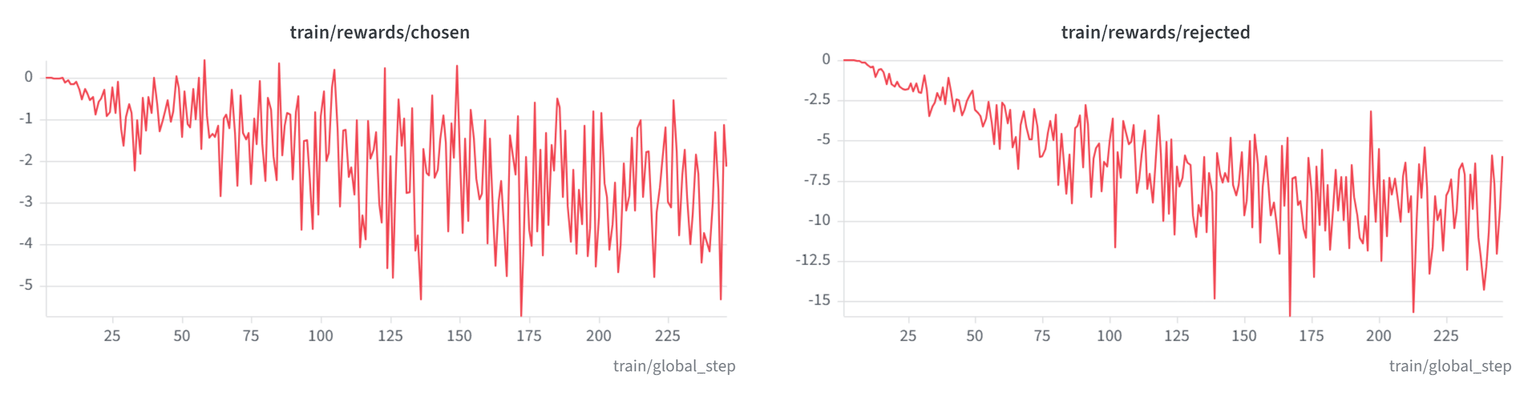

<i><b>Figure 1.</b> Implicit reward in DPO β·log(π/π_ref) of the chosen (left) and rejected (right) answers per training step.</i>

In contrast, GRPO is a genuine reinforcement learning method and is on-policy. At each step, the model generates a group of answers for every question, and each answer receives a reward computed by programs that check the output (here, a format check and a correctness check against the GSM8K reference answer). The advantage of an answer is (reward − group mean) / group standard deviation, so answers better than their group's average become more likely and the others less likely. Although GRPO is much lighter than PPO, generating answers at every step makes it more costly than DPO, and its main weakness in this particular case is the small group size. Having such few generations per question, the mean and standard deviation are very noisy, and the group can hardly play its role of baseline. Note that neither method trains a separate reward model: DPO's reward is implicit, and GRPO's comes from programs.

The choice between the two methods depends mainly on what kind of signal we have. When answers can be checked automatically by a program (math results, puzzles such as sudoku, or proofs validated by a verifier like Lean), GRPO is the natural choice. The checker provides the reward, and since the model learns from its own samples it could go beyond any fixed dataset. This comes with the condition that the model must already succeed from time to time, because if every sampled answer gets the same reward the advantages are zero and there is no learning signal. On the other hand, when there is no such verifier, but we do have human or synthetic preferences, as in writing emails or summarizing stories, DPO is the applicable option, since it only needs pairs of answers. It is cheap and stable, but its ceiling is the quality of the dataset: in our lab the preferences are synthetic (chosen answers come from a stronger model), so DPO mostly pushes the small model towards imitating it. Finally, the methods are not mutually exclusive. The pipeline seen in class chains them: SFT teaches the model to follow instructions, DPO aligns its behavior, and GRPO then improves its reasoning on verifiable tasks.

Regarding the KL-regularized objective, DPO optimizes it implicitly. For this objective, the best possible policy is known in closed form, and it links the reward of an answer to how much more likely the policy makes it compared with the reference. DPO uses this link to replace the reward by the log-ratio β·log(π/π_ref), and it trains the model to increase the probability of the chosen answer, relative to the reference, more than that of the rejected one, which is a simple classification problem on the preference pairs. The KL term is not computed either, but it is built into these log-ratios, which keep the policy tied to the reference. GRPO instead optimizes the reward directly from sampled answers, and the KL term is an optional explicit penalty weighted by β. In our experiment, with β=0 we remove it. No reference model is needed, which saves memory, but nothing anchors the policy to its starting point and stability would then rely on clipping and the learning rate. However, clipping never acts in our run, because it only cuts an update when the probability of a token has already changed by more than a factor of 1 ± epsilon (<code>epsilon = 0.28</code> in our case) with respect to its value when the completion was generated. The point here is that in our setup each batch of completions is used for a single gradient step, computed with the same model that generated it. The probability ratio is therefore always exactly 1, and the clipped fraction is 0 at every step (Figure 2, left). In practice, the only brakes in our run were the small learning rate, gradient-norm clipping (<code>max_grad_norm</code> = 1), the limited capacity of LoRA and the short training (50 steps). None of these bounds the accumulated drift, so the model could exploit the reward, for instance by learning the exact format without actually reasoning better. On the other hand, we can also look at the entropy of the model, which measures how spread its predictions are. A typical risk of RL fine-tuning without a KL term is entropy collapse, in which the model concentrates its probability on a few tokens and its completions become almost identical. Then, when we generate the completions, the learning signal could vanish, since the completions of a group would be very similar and tend to receive the same reward. In our run the entropy stays roughly stable between about 0.25 and 0.55 (Figure 2, right), so no collapse is visible, although it could appear with more training steps.

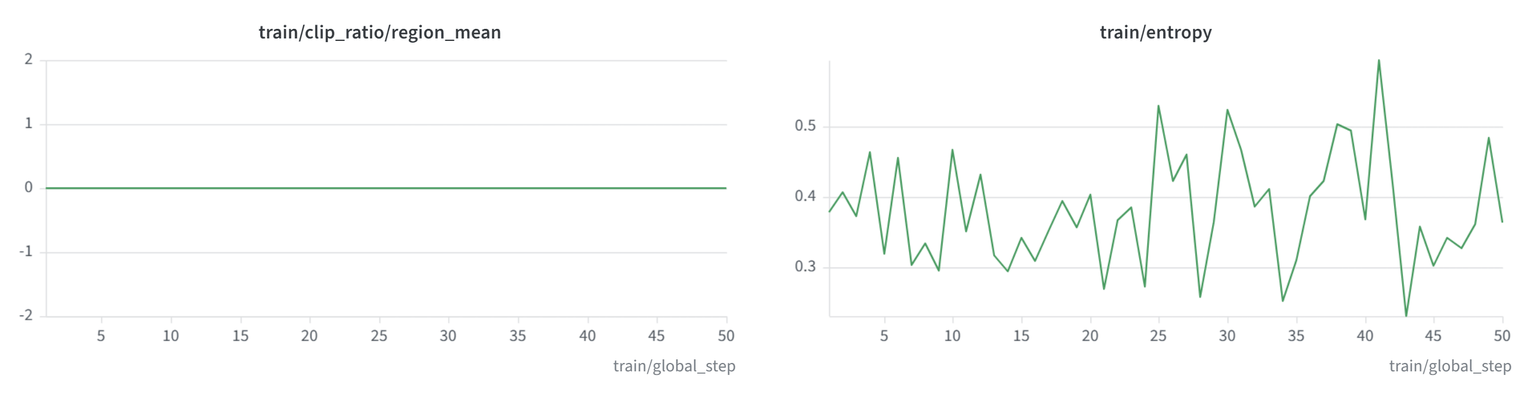

<i><b>Figure 2.</b> Fraction of clipped tokens in the GRPO run (left) and entropy of the model (right) per training step.</i>


<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 2: </b><br>

- Why can **reward model overfitting** or **reward hacking** occur in reinforcement fine-tuning?  
- How do DPO and our GRPO setup avoid relying on a learned reward model, and what risks remain?  
- Discuss the role of the **reference model** in maintaining stability.
<hr style="border:10px solid red"> </hr>
</font></h4>

<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 2: </b><br>

<hr style="border:10px solid red"> </hr>
</font></h4>

When a model is optimized against a reward model (a second network, trained on human comparisons between answers, that predicts which answer annotators would prefer), the reward model is only an approximation of what we really want, learned from a finite number of examples. Deciding which answer is better is often subjective, even among human annotators, so this approximation is imperfect. This is the source of both problems. Reward model overfitting means that the reward model fits its own training comparisons too closely, including their noise and accidental patterns, so its scores become unreliable on new answers. This matters in reinforcement fine-tuning because, as the policy changes, it generates answers that differ from those the reward model was trained on. Conversely, reward hacking appears when we optimize hard against an imperfect reward, so the policy finds answers that obtain a high score without being really better. For example, if the reward model tends to give better scores to long answers, the policy may learn to extend its responses with irrelevant content just to write more. Both DPO and GRPO try to avoid relying on a learned reward model, although, as we will see, they do not fully escape this problem.

DPO has an implicit reward, the log-ratio between the current policy and the reference model (scaled by β), so no judge network is needed. However, this reward is defined by the preference dataset, which is only a limited representation of what we want. In our lab the chosen answers were written by stronger models (GPT-4/3.5), the rejected ones by a weaker model, and the dataset is a French translation of the original. The label therefore reflects the source of the answer rather than a human judgment, so the first risk is that the model may learn superficial traits that separate both sources (style, fluency, length) instead of real quality. We can check this in the logs too. The DPO accuracy (fraction of pairs where the chosen answer gets the higher implicit reward) jumps to about 1 within the first few steps and stays there, while the margin keeps growing notably until around step 125 (Figure 3). Such a fast and stable accuracy, on pairs that the model sees only once (one epoch), suggests that the model may rely on easily detectable differences between the two sources rather than on subtle quality differences.

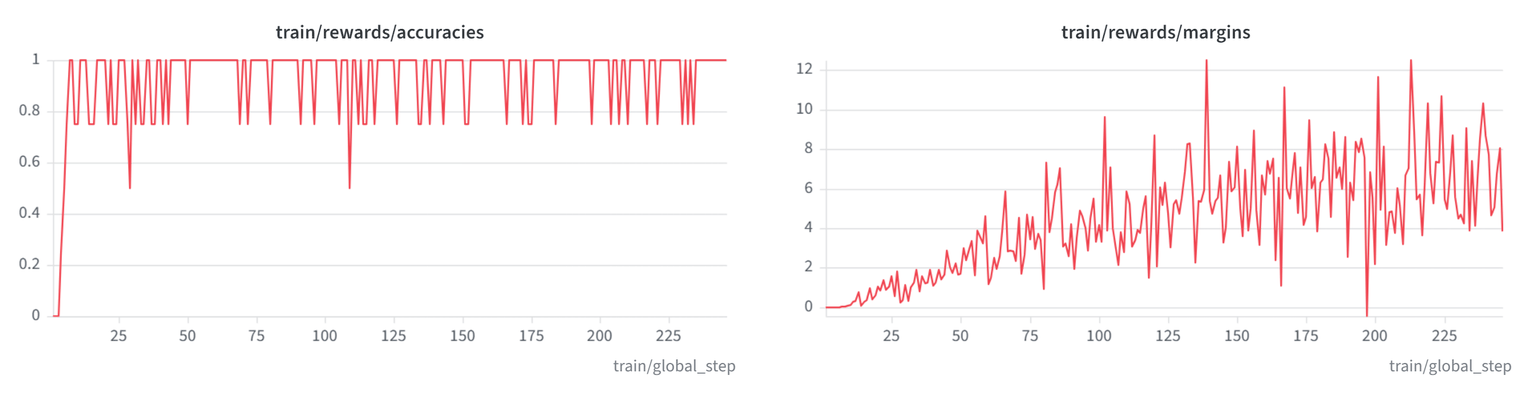

<i><b>Figure 3.</b> DPO run: preference accuracy (left) and reward margin between chosen and rejected answers (right) per training step.</i>

GRPO uses programs that check the answers, which gives deterministic rewards, but they are still a proxy. Some weaknesses can be found here. The format reward only checks the structure, so the model could learn to produce it without reasoning better. The correctness reward only looks at the final number, so a correct result reached through a wrong procedure (or by luck) is fully rewarded, and a completion truncated by the 300-token limit gets no reward, which may push the model towards shorter reasoning. This is not a marginal case, as in some batches of our run, up to 3 of the 8 completions (about 37%) reached the 300-token limit (Figure 4).

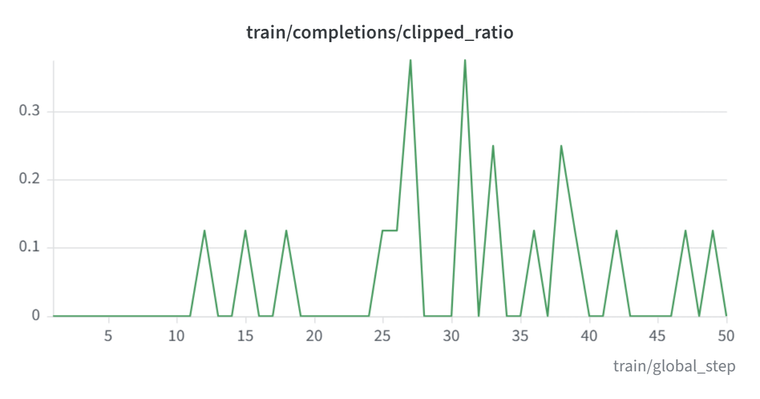

<i><b>Figure 4.</b> GRPO run: fraction of the 8 completions of each step that were truncated at the 300-token limit.</i>

About the reference model, it is what keeps this optimization stable. It is a frozen copy of the model before training (with LoRA, simply the same model with the adapters disabled) and the optimization is anchored to it. In general, this anchoring is explicit in GRPO, through a KL penalty, and implicit in DPO, through the log-ratios. This limits the drift that reward hacking needs, since without an anchor the policy can leave the region where the reward is reliable and may degrade its fluency or general abilities. In DPO the reference is built into the loss, so it is always present, with β controlling how strictly. In GRPO the KL penalty is optional, and with β=0, as in our case, it is removed. Therefore, we save memory but as noted in Answer 1, clipping never activates in our setup, so stability relies essentially on the small learning rate, gradient clipping and the small number of steps. Note that the reference does not fix a flawed reward, it only limits how far the model can go in exploiting it.

<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 3: </b><br>

- In the GSM8K setup, we used a simple binary reward for **format** and **correctness**.  
  - What are the limitations of such sparse rewards?  
  - How could you design a **richer, smoother** reward signal for math reasoning?
<hr style="border:10px solid red"> </hr>
</font></h4>

<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 3: </b><br>

<hr style="border:10px solid red"> </hr>
</font></h4>

Indeed, the main problem of sparse rewards is that if our model has difficulty performing correctly, we can find the scenario where all the answers of a group get the same reward of 0, so the parameters cannot be updated. If all the rewards are the same, the advantages are zero. Therefore, we need our model to already succeed at least occasionally from the beginning. The same can happen if the program is too lenient and considers all the answers correct. No update can be done, so a reliable program is needed to ensure a good fine-tuning. This is especially relevant in our setup, where `num_generations=2` makes it very likely that both answers of a group get the same reward. By the way, regarding our case, as we can have 1 point for format (0 or 1) and 2 points for correctness (0 or 2), we have a very limited number of values {0,1,2,3}, which gives lots of ties within a group and makes the update of the parameters difficult. Indeed this can be confirmed in our logs, where the fraction of groups whose two completions received the same reward (<code>frac_reward_zero_std</code>) fluctuates between 0 and 1 and is around 0.5 on average, so roughly half of the groups gave no learning signal. At 6 of the 50 steps (3, 8, 9, 21, 34 and 45) all groups tied, and accordingly both the loss and the gradient norm are exactly 0 at those steps (Figure 5). Moreover, the base model only solved 10% of the test problems, so many groups were likely made of two wrong answers or two correct ones. A larger variety of values would give a finer evaluation, letting the model update in the best direction more times, although this implies a more complex evaluation program and maybe a higher computational cost.

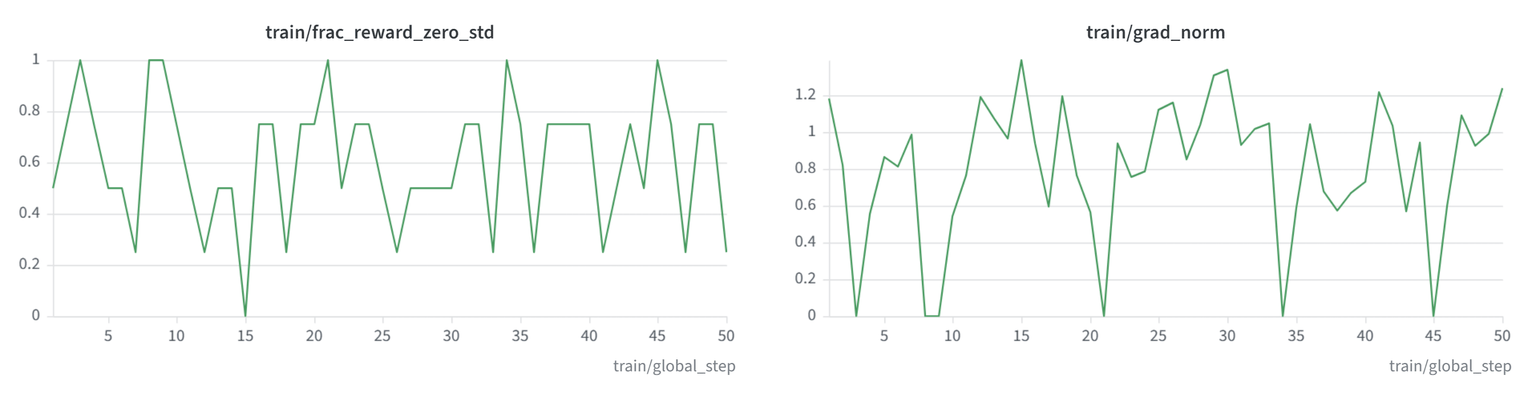

<i><b>Figure 5.</b> GRPO run: fraction of groups whose two completions got the same reward (left) and gradient norm (right) per training step. The gradient norm is exactly 0 at the steps where the loss is 0 (3, 8, 9, 21, 34 and 45).</i>

On the other hand, we also deal with the fact that we only check the format and the correctness at the end. As discussed in Answer 2, a final result given by chance or after an incorrect procedure is rewarded as a real good resolution, and can mislead the update of the parameters. Conversely, if at the end we make a small mistake, it is considered as wrong as a completely random result, which is not informative either. A last limitation concerns how correctness is checked, as the extracted text is compared with the reference as a string (`r == a`), so a correct answer written slightly differently (for instance `72.0` or `1,000` instead of `72` or `1000`) receives no reward. These false zeros add noise to the signal, since the model is penalized for how it writes the number rather than for its reasoning. A more robust check would normalize the text and compare the values as numbers.

To obtain a richer and smoother signal (one where small changes in an answer produce small changes in the reward), we have some proposals. Firstly, as GSM8K includes step-by-step solutions, we could add some checkpoints in the middle, rewarding the appearance of some intermediate values in the answer. With this, we could reward following a good procedure, which we are not currently doing. This is cheap but not perfect: a valid solution may use different steps, and the model could learn to write the numbers without really reasoning. On this line, more ambitiously, we have the possibility to add a neural network that evaluates each step of the reasoning (Lightman et al., 2023), but we add the risk of introducing a reward model in the procedure, with the possibility of reward hacking appearing. Secondly, we could introduce a softer penalty for the answers that exceed `max_completion_length`. Right now they receive 0, but it could be the case that they were following a good procedure although they exceeded the limit of tokens at the end. This has a trade-off, since the current penalty also pushes the model towards concise answers, which a softer one would reduce. Finally, another interesting point is `num_generations`. It is not a change in the reward itself, but it attacks the same problem, because with larger groups it is much less likely that all the answers get the same reward, and the group mean and standard deviation become less noisy. The cost is that generating more answers at every step is precisely the expensive part of GRPO. In (Figure 6) we can see how expensive this already is, with generation taking about 10–30 s per step, against about 0.3–0.6 s for computing the loss and about 2 ms for the rewards. Overall, none of these improvements is free. Some of them have a computational cost, and those that reward intermediate values or rely on a learned verifier are themselves proxies, which the model could satisfy without really reasoning better, connecting with the reward hacking risks discussed in Answer 2.

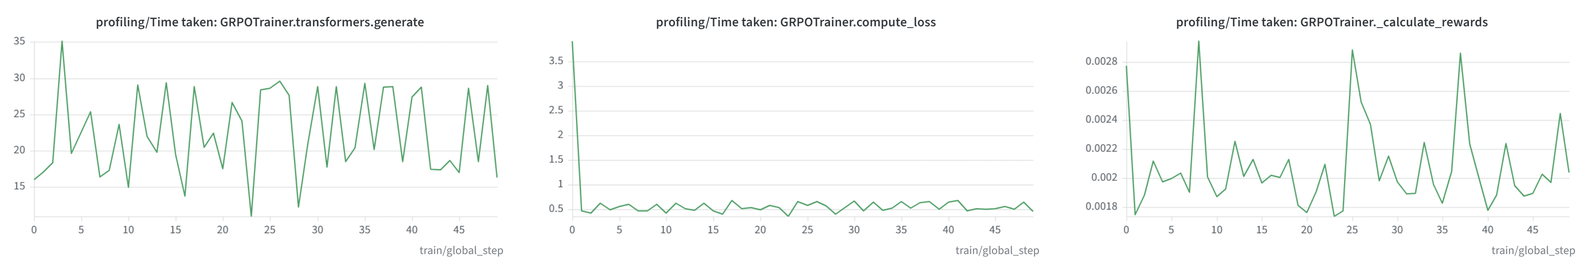

<i><b>Figure 6.</b> Time per training step (in seconds) spent generating the completions (left), computing the loss (center) and computing the rewards (right).</i>

*References:*
- Lightman et al., 2023. *Let's Verify Step by Step.* [arXiv:2305.20050](https://arxiv.org/abs/2305.20050)